In [1]:
from pathlib import Path                      # Object-oriented file and directory paths
import json                                   # Reads/writes JSON data
import subprocess                             # Runs the automated pytest suite
import sys                                    # Access Python interpreter and system

import matplotlib.pyplot as plt               # Plots and visualizations
import numpy as np                            # Numerical computing and array operations
import pandas as pd                           # Data manipulation and analysis
from scipy.stats import kendalltau            # Measures the agreement between the rankings produced by WSM and TOPSIS.

# Adding the repository root to Python's module-search path only when it is not already present. 
#This makes the local src.mcda package importable without installing the project as a package.
ROOT = Path.cwd().resolve()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

#Importing functions:
from src.mcda import (
    minmax_normalize,                         # converts mixed-scale cost/benefit criteria to a common 0-1 scale
    one_way_sensitivity,                      # varies one criterion weight and proportionally rescales the others
    rank_scores,                              # converts scores into ranks, with the largest score ranked first
    sample_weights,                           # draws valid random weight combinations for robustness analysis
    summarize_ranks,                          # calculates win frequencies and average ranks across simulations
    topsis,                                   # ranks suppliers by distance from ideal and anti-ideal solutions
    validate_problem,                         # checks the data, criterion directions, and weights before analysis
    weighted_sum,                             # calculates Weighted Sum Model scores using a matrix-vector product
)

# Improving table readability by showing up to 20 columns and four decimal places.
pd.set_option("display.max_columns", 20)
pd.set_option("display.precision", 4)

# Applying a clean chart theme and define a reusable, color-blind-conscious project palette.
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {
    "blue": "#2563EB",
    "green": "#059669",
    "orange": "#EA580C",
    "purple": "#7C3AED",
    "gray": "#64748B",
}

# A fixed random seed makes the random-weight simulation reproducible.
SEED = 2026

# Performing a check by returning a short string that gives visible confirmation that the setup cell finished.
"Environment ready"

'Environment ready'

# Choosing the Best Supplier with Mathematics: #
## Weighted scoring, TOPSIS, and sensitivity analysis in Python ##

**Course:** Math Concepts for Developers  
**Author:** Boyan Yotov  
**Data:** Fully fictional educational dataset - no real supplier information is used  
**Date:** November 2026

> **Main question:** How can normalization, weights, and distance from ideal solutions turn several conflicting supplier criteria into a transparent recommendation - and how stable is that recommendation when assumptions change?

## Notebook map ##

1. Problem formulation and learning goals
2. Fictional data and assumptions
3. Mathematical foundations
4. Weighted Sum Model (WSM)
5. TOPSIS comparison
6. Scenario and sensitivity experiments
7. Robustness checks and an outlier experiment
8. Verification, limitations, and conclusions

### What you should be able to explain after reading: ###

- Why criteria measured in euros, days, percentages, and scores cannot be added directly?
- How cost and benefit criteria require different normalization formulas?
- Why a weighted score is a dot product?
- How does TOPSIS compare each supplier with ideal and anti-ideal points?
- Why does the word *best* always depend on stated weights, data, and model assumptions?
- How sensitivity analysis separates a stable recommendation from a fragile one?


---

## Abstract ##

Supplier selection is a multi-criteria decision problem: a low price can be offset by slow delivery, while strong quality can coexist with higher risk or weaker sustainability. This project creates a transparent mathematical model for comparing six fictional suppliers across six criteria. Direction-aware min-max normalization first places every criterion on a common 0-to-1 scale. The Weighted Sum Model (WSM) then combines normalized performance with explicit criterion weights through matrix-vector multiplication. A second method, TOPSIS, evaluates closeness to an ideal supplier and distance from an anti-ideal supplier.

The baseline assumptions select **Borealis Industries** with a WSM score of approximately **0.724**, narrowly ahead of **Evergreen Manufacturing** at approximately **0.718**. TOPSIS produces the same complete ranking under baseline weights. This agreement does not make the result universally correct: scenario analysis changes the winner when quality and reliability receive more emphasis, and one-way sensitivity shows winner changes near price weights of 0.23 and 0.48. In 5,000 reproducible random-weight simulations concentrated around the baseline, Borealis wins 59.04% of WSM runs and Evergreen 40.78%; TOPSIS and WSM choose the same winner in 77.38% of runs.

The main conclusion is that mathematics can make supplier selection consistent, inspectable, and reproducible, but it cannot remove human judgment. A responsible recommendation must report the selected weights, method, assumptions, margins, and stability tests rather than only the top-ranked name.

---

# 1. Problem formulation #

## 1.1 The real-world problem ##

A buyer may need to compare offers that are strong in different ways. One supplier can be inexpensive but slow; another can be reliable but costly. There is no natural unit that allows us to add euros, days, percentages, and risk scores. A mathematical decision model therefore has to perform three translations:

1. **Business alternatives -> rows** in a decision matrix.
2. **Business criteria -> numerical columns** with explicit directions.
3. **Business preferences -> weights** whose sum is one.

The output is a ranking, not an automatic procurement decision. Commercial terms, legal checks, technical qualification, capacity, contractual risk, and stakeholder approval remain outside this simplified educational model.

## 1.2 Research questions ##

1. How does direction-aware normalization make heterogeneous criteria comparable?
2. Do WSM and TOPSIS agree under the baseline assumptions?
3. Which assumptions can change the winning supplier?
4. Is the result robust to many plausible weight combinations?
5. How can a model be communicated without hiding value judgments?

## 1.3 Hypothesis

The two methods are expected to agree on the strongest suppliers under baseline weights, but the winner is expected to change when price or quality/reliability receives substantially more weight. A small winning margin should be treated as evidence for more review, not false precision.


## 1.4 Scope, assumptions, and success criteria ##

### Included ###

- six fictional alternatives and six numerical criteria
- three cost criteria and three benefit criteria
- WSM and TOPSIS rankings
- scenario, one-way, random-weight, leave-one-criterion-out, and outlier experiments
- reusable Python functions with automated tests

### Deliberate simplifications ###

- The data are point estimates, not audited observations or contractual guarantees.
- Criteria are treated as independent, although real criteria can be correlated.
- WSM assumes that poor performance on one criterion may be compensated by strong performance on another.
- Baseline weights are illustrative and are not claimed to represent any company policy.
- No mandatory threshold is enforced. In a real process, minimum quality or compliance requirements should be applied before scoring.

### Success criteria ###

The project is successful if the notebook is reproducible, formulas match the code, all automated tests pass, the recommendation can be traced to explicit assumptions, and ranking instability is reported rather than concealed.


# 2. Data and decision assumptions #

The dataset is intentionally small enough to calculate by hand. Every value is synthetic. This avoids confidentiality concerns and keeps attention on the mathematics.

A **cost criterion** is better when smaller. A **benefit criterion** is better when larger. The risk score is an invented 1-to-5 assessment where 1 indicates lower risk and 5 indicates higher risk.

In [8]:
# Loading the decision-model configuration and fictional supplier dataset,
# then validating them before any calculations are performed.

# Reading the UTF-8 JSON text and converting it into a Python dictionary.
config_path = ROOT / "config" / "decision_problem.json"
config = json.loads(config_path.read_text(encoding="utf-8"))

# Extracting the ordered criterion list, cost/benefit directions, and baseline weights.
# Preserving criterion order is important for matrix calculations and consistent displays.
criteria = config["criteria"]
directions = config["directions"]
baseline_weights = config["baseline_weights"]

# Loading the CSV into a pandas DataFrame and using supplier names as row labels.
data_path = ROOT / "data" / "fictional_suppliers.csv"
suppliers = pd.read_csv(data_path).set_index("Supplier")

# A clear error if columns, numeric data, directions, or weights are invalid.
validate_problem(suppliers, criteria, directions, baseline_weights)

# Display the validated raw decision matrix.
suppliers

,Unit Price (EUR),Delivery Time (days),Quality Score (%),On-Time Delivery (%),Sustainability Score,Risk Score
Supplier,,,,,,
Atlas Components,94,12,92,94,68,3.0
Borealis Industries,101,8,96,98,85,1.5
Cedar Supply,89,15,88,90,76,3.8
Delta Partners,98,9,94,96,80,2.0
Evergreen Manufacturing,104,7,97,97,92,1.8
Falcon Solutions,92,11,91,93,70,2.7


## 2.1 Data dictionary and weight rationale ##

The baseline gives price and quality the greatest weight (0.25 each), followed by delivery time and on-time delivery (0.15 each). Sustainability and risk receive 0.10 each. These choices are assumptions to test, not facts discovered from the data.

In [9]:
# Creating a data dictionary that explains every decision criterion,
# including its measurement unit, optimization direction, weight, and business meaning.

# Mapping each criterion to the unit used in the source dataset.
units = {
    "Unit Price (EUR)": "EUR per unit",
    "Delivery Time (days)": "calendar days",
    "Quality Score (%)": "percent",
    "On-Time Delivery (%)": "percent",
    "Sustainability Score": "0-100 points",
    "Risk Score": "1-5 points",
}

# Including interpretations for each variable and whether lower or higher values are preferable.
meaning = {
    "Unit Price (EUR)": "Quoted unit price; lower is preferred",
    "Delivery Time (days)": "Expected lead time; lower is preferred",
    "Quality Score (%)": "Expected accepted units; higher is preferred",
    "On-Time Delivery (%)": "Historical-style reliability estimate; higher is preferred",
    "Sustainability Score": "Composite educational rating; higher is preferred",
    "Risk Score": "Composite educational risk estimate; lower is preferred",
}

# Converting the dictionaries to aligned Series objects. pandas aligns rows by criterion name,
# preventing accidental dependence on dictionary display order.
data_dictionary = pd.DataFrame({
    "Direction": pd.Series(directions),
    "Baseline weight": pd.Series(baseline_weights),
    "Unit": pd.Series(units),
    "Interpretation": pd.Series(meaning),
})

# Display the completed documentation table.
data_dictionary

,Direction,Baseline weight,Unit,Interpretation
Unit Price (EUR),cost,0.25,EUR per unit,Quoted unit price; lower is preferred
Delivery Time (days),cost,0.15,calendar days,Expected lead time; lower is preferred
Quality Score (%),benefit,0.25,percent,Expected accepted units; higher is preferred
On-Time Delivery (%),benefit,0.15,percent,Historical-style reliability estimate; higher ...
Sustainability Score,benefit,0.10,0-100 points,Composite educational rating; higher is preferred
Risk Score,cost,0.10,1-5 points,Composite educational risk estimate; lower is ...


## 2.2 Exploratory view of the raw values ##

The small multiples below deliberately keep the original units. The chart makes the conflicts visible: Evergreen is strongest on several benefit criteria but has the highest price; Cedar is cheapest but slower and weaker on quality and reliability.


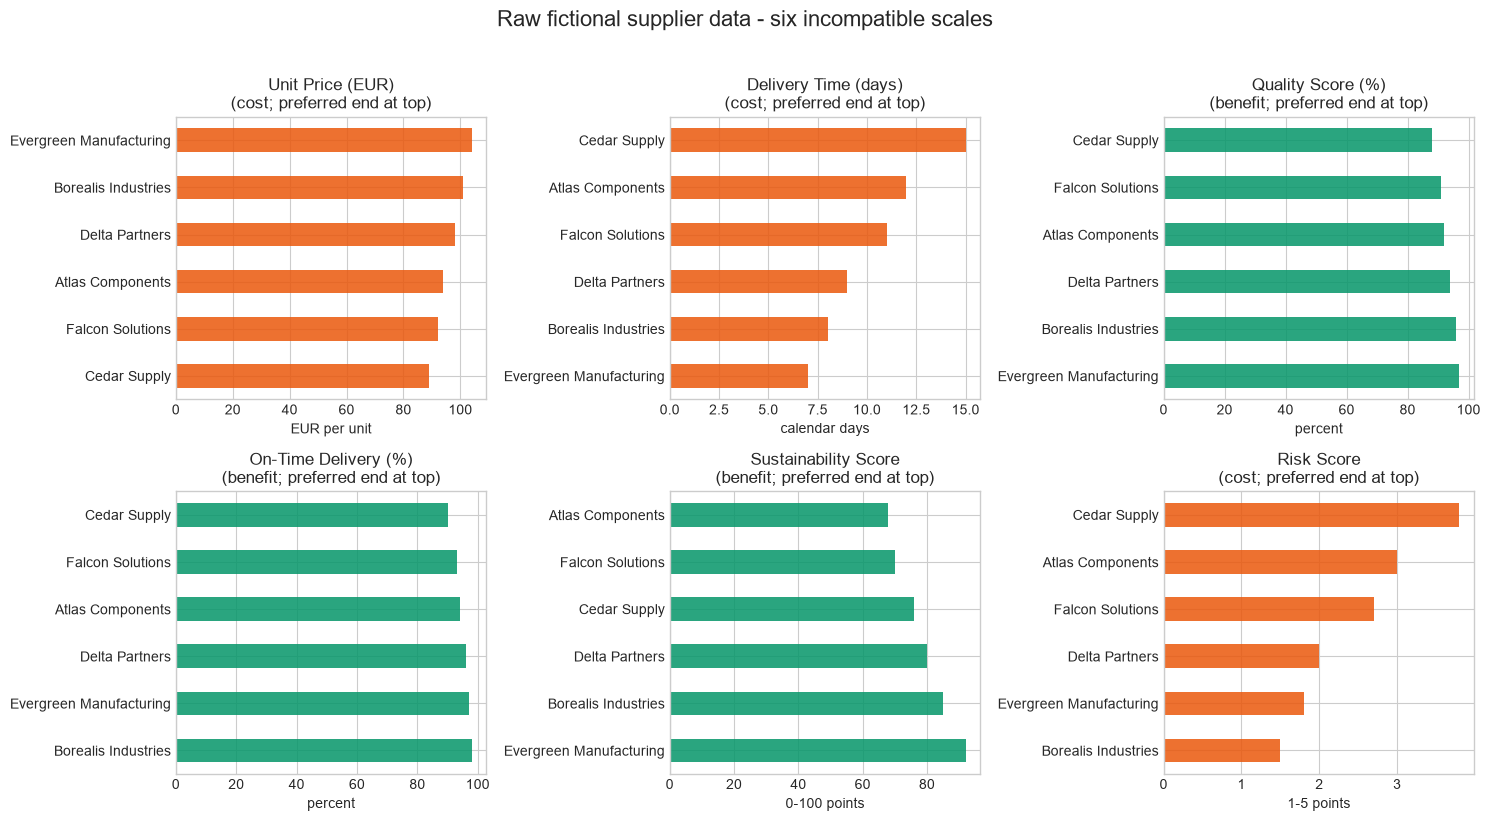

In [10]:
# Comparing all suppliers on the original measurement scales before normalization.
# A 2-by-3 grid provides one horizontal bar chart for each of the six criteria.
fig, axes = plt.subplots(2, 3, figsize=(15, 8))

# Pairing each subplot with one criterion. axes.flat turns the grid into a one-dimensional iterator.
for ax, criterion in zip(axes.flat, criteria):
    # Sort so the preferred values appear toward the top of each horizontal chart.
    # Cost criteria are sorted ascending; benefit criteria are sorted descending.
    ordered = suppliers[criterion].sort_values(ascending=directions[criterion] == "cost")

    # Using green for benefits and orange for costs to reinforce criterion direction visually.
    color = COLORS["green"] if directions[criterion] == "benefit" else COLORS["orange"]
    ordered.plot(kind="barh", ax=ax, color=color, alpha=0.85)

    # Adding titles, units, and clean axis labels.
    ax.set_title(f"{criterion}\n({directions[criterion]}; preferred end at top)")
    ax.set_xlabel(units[criterion])
    ax.set_ylabel("")

# Adding one shared title, resolve overlaps, and render the figure.
plt.suptitle("Raw fictional supplier data - six incompatible scales", fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 2.3 Why a raw sum is invalid ##

Adding the raw columns would mix dimensions: one euro plus one day plus one percentage point has no meaningful interpretation. Large-number columns would dominate merely because of their units. The following intentionally incorrect calculation illustrates the problem; it is not used for any recommendation.


In [11]:
# Demonstration of why adding raw criterion values is mathematically invalid.
# The columns use incompatible units and ranges, so large-scale variables would dominate
# merely because of their measurement scale rather than their decision importance.

naive_raw_sum = (
    suppliers[criteria]
    .sum(axis=1)                 # Add across criteria for each supplier (axis=1 means rows).
    .sort_values(ascending=False)
    .rename("Invalid raw sum")
)

# Converting the Series to a one-column table for a clearer display.
naive_raw_sum.to_frame()

,Invalid raw sum
Supplier,
Evergreen Manufacturing,398.8
Borealis Industries,389.5
Delta Partners,379.0
Atlas Components,363.0
Cedar Supply,361.8
Falcon Solutions,359.7
